In [2]:
from pathlib import Path

print("Current notebook directory:")
print(Path.cwd())

print("\nFiles and folders here:")
for item in Path.cwd().iterdir():
    print(item.name)

Current notebook directory:
c:\Users\ANKIT TRIPATHI\Downloads\ecommerce-delivery-logistics-analysis-main\ecommerce-delivery-logistics-analysis-main\notebooks

Files and folders here:
01_data_inspection.ipynb
02_eda.ipynb
Logistics_KPI_Analysis.ipynb


In [3]:
from pathlib import Path
import pandas as pd

# Notebook ke parent folder ko project root banayein
PROJECT_ROOT = Path.cwd().parent
INTERIM_FOLDER = PROJECT_ROOT / "data" / "interim"

print("Project root:", PROJECT_ROOT)
print("Interim folder exists:", INTERIM_FOLDER.exists())
print("Files in interim folder:")

if INTERIM_FOLDER.exists():
    for file in INTERIM_FOLDER.iterdir():
        print(file.name)

Project root: c:\Users\ANKIT TRIPATHI\Downloads\ecommerce-delivery-logistics-analysis-main\ecommerce-delivery-logistics-analysis-main
Interim folder exists: True
Files in interim folder:
.gitkeep


In [4]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

for folder in [
    PROJECT_ROOT / "data",
    PROJECT_ROOT / "data" / "raw",
    PROJECT_ROOT / "data" / "interim",
]:
    print(f"\nFolder: {folder}")
    print("Exists:", folder.exists())

    if folder.exists():
        for item in folder.iterdir():
            print(" -", item.name)


Folder: c:\Users\ANKIT TRIPATHI\Downloads\ecommerce-delivery-logistics-analysis-main\ecommerce-delivery-logistics-analysis-main\data
Exists: True
 - interim
 - processed
 - raw

Folder: c:\Users\ANKIT TRIPATHI\Downloads\ecommerce-delivery-logistics-analysis-main\ecommerce-delivery-logistics-analysis-main\data\raw
Exists: True
 - .gitkeep

Folder: c:\Users\ANKIT TRIPATHI\Downloads\ecommerce-delivery-logistics-analysis-main\ecommerce-delivery-logistics-analysis-main\data\interim
Exists: True
 - .gitkeep


In [5]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
RAW_FOLDER = PROJECT_ROOT / "data" / "raw"

csv_files = sorted(RAW_FOLDER.glob("*.csv"))

print("CSV files found:", len(csv_files))

for file in csv_files:
    print(file.name)

CSV files found: 9
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_orders_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [6]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
RAW_FOLDER = PROJECT_ROOT / "data" / "raw"

for file in sorted(RAW_FOLDER.glob("*.csv")):
    df = pd.read_csv(file, nrows=5)

    print(f"\nFile: {file.name}")
    print("Columns:", len(df.columns))
    print("Column names:", df.columns.tolist())


File: olist_customers_dataset.csv
Columns: 5
Column names: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

File: olist_geolocation_dataset.csv
Columns: 5
Column names: ['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']

File: olist_order_items_dataset.csv
Columns: 7
Column names: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

File: olist_order_payments_dataset.csv
Columns: 5
Column names: ['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

File: olist_order_reviews_dataset.csv
Columns: 7
Column names: ['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

File: olist_orders_dataset.csv
Columns: 8
Column names: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'orde

In [7]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
RAW_FOLDER = PROJECT_ROOT / "data" / "raw"

orders = pd.read_csv(
    RAW_FOLDER / "olist_orders_dataset.csv"
)

print("Dataset shape:", orders.shape)

print("\nOrder status counts:")
print(orders["order_status"].value_counts(dropna=False))

print("\nMissing delivery dates:")
print(
    orders[
        [
            "order_delivered_customer_date",
            "order_estimated_delivery_date"
        ]
    ].isna().sum()
)

print("\nSample records:")
print(
    orders[
        [
            "order_id",
            "order_status",
            "order_delivered_customer_date",
            "order_estimated_delivery_date"
        ]
    ].head()
)

Dataset shape: (99441, 8)

Order status counts:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Missing delivery dates:
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Sample records:
                           order_id order_status  \
0  e481f51cbdc54678b7cc49136f2d6af7    delivered   
1  53cdb2fc8bc7dce0b6741e2150273451    delivered   
2  47770eb9100c2d0c44946d9cf07ec65d    delivered   
3  949d5b44dbf5de918fe9c16f97b45f8a    delivered   
4  ad21c59c0840e6cb83a9ceb5573f8159    delivered   

  order_delivered_customer_date order_estimated_delivery_date  
0           2017-10-10 21:25:13           2017-10-18 00:00:00  
1           2018-08-07 15:27:45           2018-08-13 00:00:00  
2           2018-08-17 18:06:29           2018-09-04 00:00:00  
3           2017-12-02 00:28:42           201

In [8]:
import pandas as pd

# Convert date columns into datetime format
orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    errors="coerce"
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"],
    errors="coerce"
)

# Keep delivered orders only
delivered = orders[
    orders["order_status"] == "delivered"
].copy()

# Exclude records without actual delivery dates
delivered = delivered.dropna(
    subset=["order_delivered_customer_date"]
)

# Calculate delivery status
delivered["delivery_performance"] = (
    delivered["order_delivered_customer_date"]
    <= delivered["order_estimated_delivery_date"]
).map({
    True: "On Time",
    False: "Late"
})

# Summarize results
delivery_summary = delivered["delivery_performance"].value_counts()

on_time = (delivered["delivery_performance"] == "On Time").sum()
late = (delivered["delivery_performance"] == "Late").sum()
total = len(delivered)

on_time_rate = on_time / total * 100
late_rate = late / total * 100

print("Delivered orders analyzed:", total)
print("On-time orders:", on_time)
print("Late orders:", late)
print(f"On-time delivery rate: {on_time_rate:.2f}%")
print(f"Late delivery rate: {late_rate:.2f}%")

Delivered orders analyzed: 96470
On-time orders: 88644
Late orders: 7826
On-time delivery rate: 91.89%
Late delivery rate: 8.11%


In [9]:
# Compare calendar dates, not timestamps
delivered["delivery_performance"] = (
    delivered["order_delivered_customer_date"].dt.normalize()
    <= delivered["order_estimated_delivery_date"].dt.normalize()
).map({
    True: "On Time",
    False: "Late"
})

on_time = (delivered["delivery_performance"] == "On Time").sum()
late = (delivered["delivery_performance"] == "Late").sum()
total = len(delivered)

print("Delivered orders analyzed:", total)
print("On-time orders:", on_time)
print("Late orders:", late)
print(f"On-time delivery rate: {on_time / total * 100:.2f}%")
print(f"Late delivery rate: {late / total * 100:.2f}%")

Delivered orders analyzed: 96470
On-time orders: 89936
Late orders: 6534
On-time delivery rate: 93.23%
Late delivery rate: 6.77%


In [10]:
# Calculate delivery delay in calendar days
delivered["delivery_delay_days"] = (
    delivered["order_delivered_customer_date"].dt.normalize()
    - delivered["order_estimated_delivery_date"].dt.normalize()
).dt.days

# Keep only late orders
late_orders = delivered[
    delivered["delivery_delay_days"] > 0
].copy()

print("Late orders:", len(late_orders))
print(
    "Average delay (days):",
    round(late_orders["delivery_delay_days"].mean(), 2)
)
print(
    "Median delay (days):",
    round(late_orders["delivery_delay_days"].median(), 2)
)
print(
    "Maximum delay (days):",
    late_orders["delivery_delay_days"].max()
)

Late orders: 6534
Average delay (days): 10.62
Median delay (days): 7.0
Maximum delay (days): 188


In [11]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
RAW_FOLDER = PROJECT_ROOT / "data" / "raw"

customers = pd.read_csv(
    RAW_FOLDER / "olist_customers_dataset.csv"
)

# Add customer state to delivered orders
delivery_state = delivered.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="one_to_one"
)

# Summarize delivery performance by state
state_summary = (
    delivery_state
    .groupby("customer_state")
    .agg(
        total_orders=("order_id", "count"),
        on_time_orders=("delivery_performance",
                        lambda s: (s == "On Time").sum()),
        late_orders=("delivery_performance",
                     lambda s: (s == "Late").sum())
    )
    .reset_index()
)

state_summary["on_time_rate_pct"] = (
    state_summary["on_time_orders"]
    / state_summary["total_orders"] * 100
).round(2)

state_summary["late_rate_pct"] = (
    state_summary["late_orders"]
    / state_summary["total_orders"] * 100
).round(2)

# Avoid ranking states with very few orders
state_summary = (
    state_summary[state_summary["total_orders"] >= 100]
    .sort_values("late_rate_pct", ascending=False)
)

print(state_summary.to_string(index=False))

customer_state  total_orders  on_time_orders  late_orders  on_time_rate_pct  late_rate_pct
            AL           397             312           85             78.59          21.41
            MA           717             592          125             82.57          17.43
            SE           335             284           51             84.78          15.22
            PI           476             410           66             86.13          13.87
            CE          1279            1103          176             86.24          13.76
            BA          3256            2860          396             87.84          12.16
            RJ         12350           10855         1495             87.89          12.11
            PA           946             840          106             88.79          11.21
            ES          1995            1781          214             89.27          10.73
            PB           517             463           54             89.56          10.44

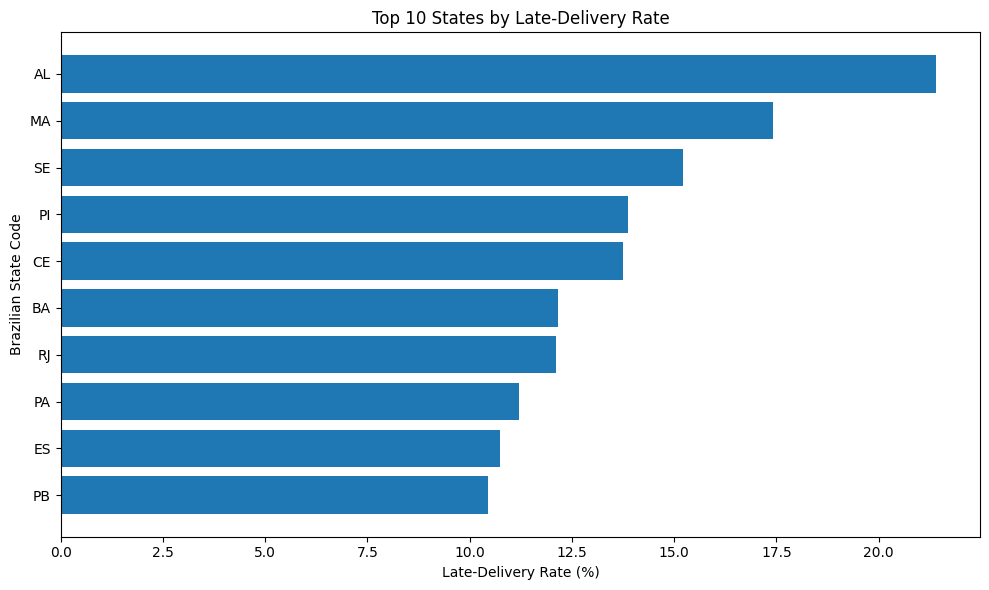

In [12]:
import matplotlib.pyplot as plt

# Select the 10 states with the highest late-delivery rates
top_10_late_states = (
    state_summary
    .sort_values("late_rate_pct", ascending=False)
    .head(10)
    .sort_values("late_rate_pct", ascending=True)
)

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_10_late_states["customer_state"],
    top_10_late_states["late_rate_pct"]
)

plt.title("Top 10 States by Late-Delivery Rate")
plt.xlabel("Late-Delivery Rate (%)")
plt.ylabel("Brazilian State Code")
plt.tight_layout()
plt.show()

In [13]:
# Extract the month when each order was purchased
delivered["purchase_month"] = (
    delivered["order_purchase_timestamp"]
    .astype("datetime64[ns]")
    .dt.to_period("M")
    .astype(str)
)

# Summarize monthly delivery performance
monthly_delivery = (
    delivered
    .groupby("purchase_month")
    .agg(
        total_orders=("order_id", "count"),
        late_orders=(
            "delivery_performance",
            lambda s: (s == "Late").sum()
        ),
        on_time_orders=(
            "delivery_performance",
            lambda s: (s == "On Time").sum()
        )
    )
    .reset_index()
)

monthly_delivery["late_rate_pct"] = (
    monthly_delivery["late_orders"]
    / monthly_delivery["total_orders"] * 100
).round(2)

print(monthly_delivery.to_string(index=False))

purchase_month  total_orders  late_orders  on_time_orders  late_rate_pct
       2016-09             1            1               0         100.00
       2016-10           265            2             263           0.75
       2016-12             1            0               1           0.00
       2017-01           750           22             728           2.93
       2017-02          1653           49            1604           2.96
       2017-03          2546          116            2430           4.56
       2017-04          2303          151            2152           6.56
       2017-05          3545          106            3439           2.99
       2017-06          3135           95            3040           3.03
       2017-07          3872          108            3764           2.79
       2017-08          4193          122            4071           2.91
       2017-09          4150          182            3968           4.39
       2017-10          4478          187          

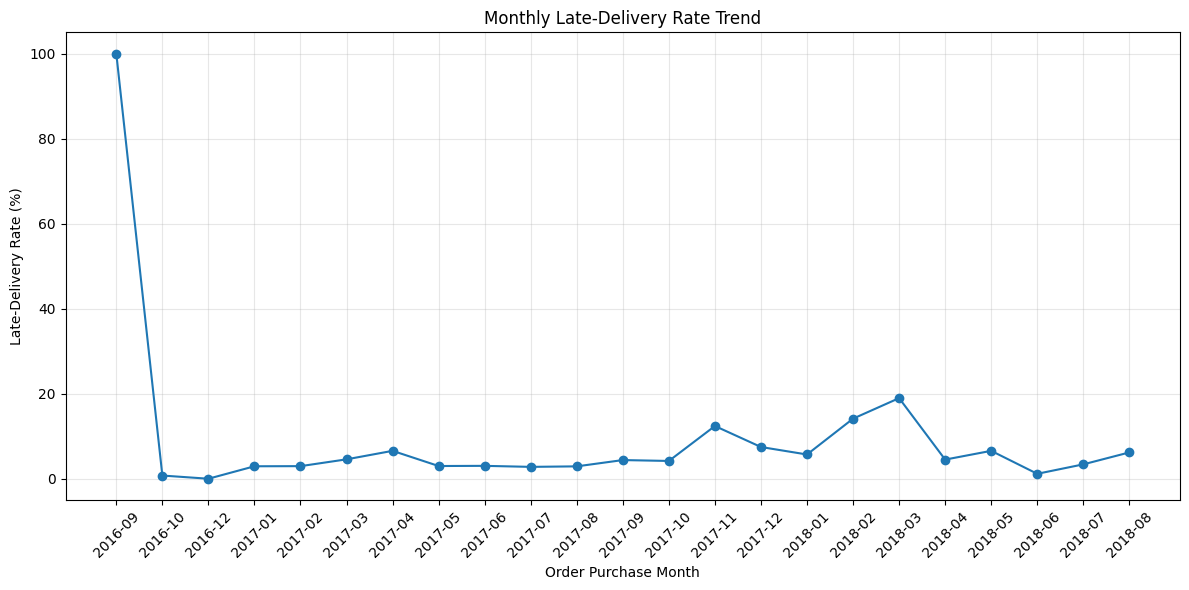

In [14]:
import matplotlib.pyplot as plt

# Sort months in chronological order
monthly_delivery = monthly_delivery.sort_values("purchase_month")

# Plot monthly late-delivery rate
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_delivery["purchase_month"],
    monthly_delivery["late_rate_pct"],
    marker="o"
)

plt.title("Monthly Late-Delivery Rate Trend")
plt.xlabel("Order Purchase Month")
plt.ylabel("Late-Delivery Rate (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

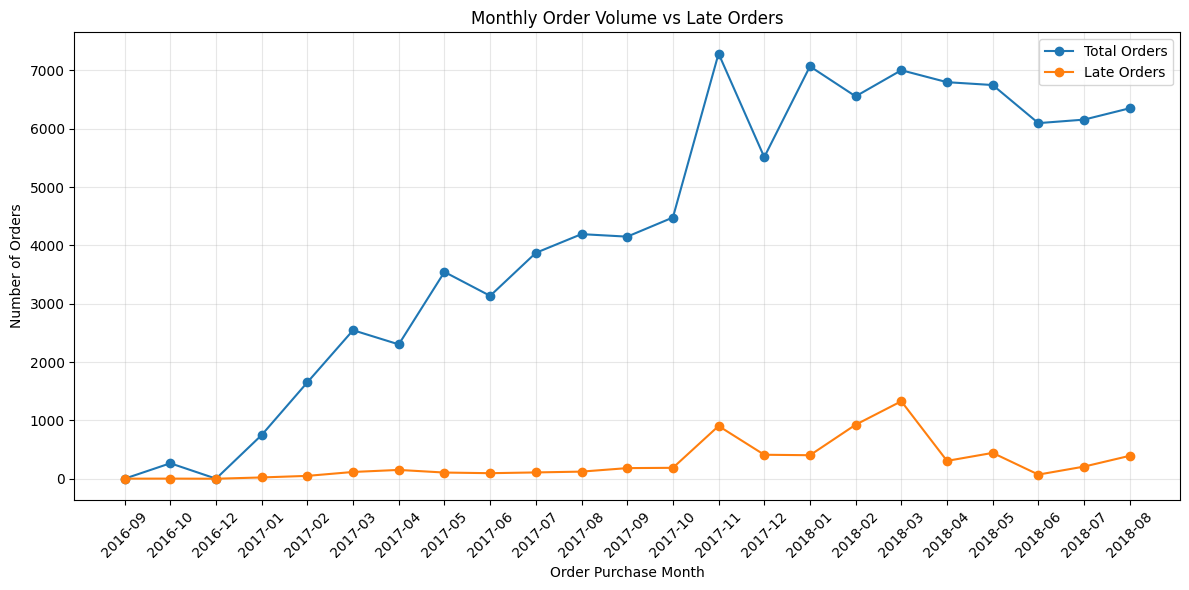

In [15]:
import matplotlib.pyplot as plt

# Ensure months are in chronological order
monthly_delivery = monthly_delivery.sort_values("purchase_month")

# Compare total orders and late orders by month
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_delivery["purchase_month"],
    monthly_delivery["total_orders"],
    marker="o",
    label="Total Orders"
)

plt.plot(
    monthly_delivery["purchase_month"],
    monthly_delivery["late_orders"],
    marker="o",
    label="Late Orders"
)

plt.title("Monthly Order Volume vs Late Orders")
plt.xlabel("Order Purchase Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
# Identify the month with the highest late-delivery rate
highest_late_rate = monthly_delivery.loc[
    monthly_delivery["late_rate_pct"].idxmax()
]

# Identify the month with the highest number of late orders
highest_late_count = monthly_delivery.loc[
    monthly_delivery["late_orders"].idxmax()
]

# Identify the month with the highest order volume
highest_order_volume = monthly_delivery.loc[
    monthly_delivery["total_orders"].idxmax()
]

print("Highest late-delivery rate:")
print(highest_late_rate)

print("\nHighest number of late orders:")
print(highest_late_count)

print("\nHighest order volume:")
print(highest_order_volume)

Highest late-delivery rate:
purchase_month    2016-09
total_orders            1
late_orders             1
on_time_orders          0
late_rate_pct       100.0
Name: 0, dtype: object

Highest number of late orders:
purchase_month    2018-03
total_orders         7003
late_orders          1328
on_time_orders       5675
late_rate_pct       18.96
Name: 17, dtype: object

Highest order volume:
purchase_month    2017-11
total_orders         7288
late_orders           904
on_time_orders       6384
late_rate_pct        12.4
Name: 13, dtype: object


In [17]:
print("Number of months:", len(monthly_delivery))

print("\nLast 6 months in the analysis:")
print(monthly_delivery.tail(6).to_string(index=False))

Number of months: 23

Last 6 months in the analysis:
purchase_month  total_orders  late_orders  on_time_orders  late_rate_pct
       2018-03          7003         1328            5675          18.96
       2018-04          6798          306            6492           4.50
       2018-05          6749          443            6306           6.56
       2018-06          6096           71            6025           1.16
       2018-07          6156          208            5948           3.38
       2018-08          6351          393            5958           6.19


In [18]:
# Compare monthly delivery counts and late rates
check_months = monthly_delivery[
    monthly_delivery["purchase_month"].isin(
        ["2018-02", "2018-03", "2018-04", "2018-05"]
    )
]

print(check_months.to_string(index=False))

# Inspect the actual delivery delay for March 2018 orders
march_orders = delivered[
    delivered["purchase_month"] == "2018-03"
].copy()

print("\nMarch 2018 delivery performance:")
print(march_orders["delivery_performance"].value_counts())

print("\nMarch 2018 delay in days:")
print(march_orders["delivery_delay_days"].describe())

purchase_month  total_orders  late_orders  on_time_orders  late_rate_pct
       2018-02          6555          926            5629          14.13
       2018-03          7003         1328            5675          18.96
       2018-04          6798          306            6492           4.50
       2018-05          6749          443            6306           6.56

March 2018 delivery performance:
delivery_performance
On Time    5675
Late       1328
Name: count, dtype: int64

March 2018 delay in days:
count    7003.000000
mean       -6.427674
std        10.776640
min      -147.000000
25%       -13.000000
50%        -8.000000
75%        -2.000000
max        76.000000
Name: delivery_delay_days, dtype: float64


In [19]:
# Inspect the 10 most delayed orders from March 2018
march_late_orders = march_orders[
    march_orders["delivery_delay_days"] > 0
].copy()

columns_to_check = [
    "order_id",
    "order_purchase_timestamp",
    "order_estimated_delivery_date",
    "order_delivered_customer_date",
    "delivery_delay_days"
]

print(
    march_late_orders
    .sort_values("delivery_delay_days", ascending=False)
    [columns_to_check]
    .head(10)
    .to_string(index=False)
)

                        order_id order_purchase_timestamp order_estimated_delivery_date order_delivered_customer_date  delivery_delay_days
e2af4ae300d48b96b78846e01a26c034      2018-03-06 23:27:33                    2018-04-03           2018-06-18 17:38:55                   76
00d1289d5125017a90e528b5a7cee91f      2018-03-15 11:11:52                    2018-04-06           2018-06-19 18:42:26                   74
fd4db108a62ede2be6aa8ef940b04fee      2018-03-07 20:10:55                    2018-04-02           2018-06-01 17:02:26                   60
416536d8c07c9cfd3cb14e229ec424a5      2018-03-10 09:08:34                    2018-04-03           2018-06-01 20:56:18                   59
88c73414c84d0729fdfc26ad5442963e      2018-03-17 09:32:16                    2018-03-29           2018-05-24 22:22:27                   56
f976bd9178b8f3927dbf9f4b5f9e7f16      2018-03-04 20:44:25                    2018-03-26           2018-05-18 18:48:43                   53
0feaee28abc2453bef40e3718f5